<a href="https://colab.research.google.com/github/AntonyRMV26/GRUPO-1---Ingenier-a-del-Conocimiento/blob/main/Actividad2_CNN_Beans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="center">

# 🌱 Clasificación de Enfermedades en Hojas de Frijol con Redes Neuronales Convolucionales

### UNIVERSIDAD NACIONAL DEL CENTRO DEL PERÚ
**Facultad de Ingeniería de Sistemas**

**Evaluación Parcial — Actividad 2: Red Neuronal Convolucional sobre Dataset de Imagen Real**

</div>

---

### 📑 Índice de secciones y pasos

| Sección | Pasos |
|:---|:---|
| **A. Presentación** | A1 Curso, semestre y fecha · A2 Integrantes · A3 Dataset y justificación · A4 Descripción del problema · A5 Uso de GPU |
| **B. Carga, exploración y preprocesamiento** | B1 Carga · B2 Dimensiones · B3 Grilla de ejemplos · B4 Distribución de clases · B5 Normalización y reshape · B6 Validación estratificada · B7 Resumen numérico |
| **C. CNN base** | C1 Arquitectura · C2 Compilación · C3 Summary y parámetros · C4 Entrenamiento · C5 Curvas · C6 Diagnóstico de overfitting |
| **D. CNN mejorada** | D1 Técnicas de regularización · D2 Entrenamiento con callbacks · D3 Curvas · D4 Comparación con la CNN base |
| **E. Optimizadores** | E1 Entrenamiento con varios optimizadores · E2 val_accuracy en un mismo gráfico · E3 Análisis de convergencia |
| **F. Evaluación rigurosa (test)** | F1 Accuracy global · F2 Classification report · F3 Matriz de confusión · F4 Curvas ROC · F5 Top 3 confusiones · F6 Errores visuales |
| **G. Conclusiones** | G1 Resumen · G2 Impacto de la regularización · G3 Confusiones y causas · G4 Lecciones aprendidas · G5 Limitaciones y mejoras |

---
# SECCIÓN A — Presentación

## A1 · Curso, semestre y fecha

| | |
|---|---|
| **Curso** | Ingeniería del Conocimiento (ISO56B) |
| **Semestre** | V (2026-II) |
| **Fecha** | 23/10/2026 |
| **Docente** | Msc. Jaime Antonio Huaytalla Pariona |

## A2 · Integrantes del grupo

| N.° | Apellidos y nombres | Código |
|:---:|---|---|
| 1 | Bendezu Arana, Joss Erick | *2024200180K* |
| 2 | Briceño Carrión, Polmar Yacid | *2024200182M* |
| 3 | Morales Huaman, Jhordan Aldair | *2024200194L* |
| 4 | Morales Valverde, Antony Rodrigo | *(completar)* |

## A3 · Dataset elegido, fuente y justificación

- **Nombre:** Beans Disease Dataset (`beans`), del Makerere AI Lab.
- **Fuente (URL):** https://www.tensorflow.org/datasets/catalog/beans
- **Origen del dataset:** https://github.com/AI-Lab-Makerere/ibean/
- **Carga en este notebook:** desde el repositorio oficial de Hugging Face (`AI-Lab-Makerere/beans`), que contiene la misma colección y las mismas particiones que TensorFlow Datasets.
- **Contenido:** 1 295 fotografías RGB de 500 × 500 píxeles (1 034 de entrenamiento, 133 de validación y 128 de prueba) de hojas de frijol, con 3 clases: `angular_leaf_spot`, `bean_rust` y `healthy`.

**Justificación de la elección.** Entre todos los datasets de imágenes que revisamos, elegimos Beans por varias razones. Primero, son fotos tomadas en campo con celular y no imágenes de laboratorio, así que tienen fondos de tierra, sombras, hojas dobladas y distintas luces, y eso hace que el problema se parezca más a la realidad. Segundo, cumple lo que pide la consigna: son más de 1 000 imágenes, tiene 3 clases, son datos reales y no es MNIST ni Fashion-MNIST, además de que no lo habíamos trabajado en clase. Tercero, su tamaño es manejable para entrenar varias veces en la GPU T4 de Colab, lo que nos permite comparar la CNN base, la mejorada y varios optimizadores sin esperar horas. Y por último, nos pareció un tema con sentido práctico: el frijol también se cultiva en nuestro país, y reconocer a tiempo una enfermedad en la hoja puede ayudar a que los agricultores actúen antes de perder la cosecha.

## A4 · Descripción del problema de clasificación

Nuestro problema es de **clasificación de imágenes en tres clases**: dada la fotografía de una hoja de frijol, el modelo debe decidir si está sana (`healthy`) o si tiene mancha angular (`angular_leaf_spot`) o roya (`bean_rust`). Ambas enfermedades dejan manchas en la hoja, pero con forma y color distintos, y en etapas tempranas pueden parecerse entre sí o incluso a una hoja sana. Para resolverlo construimos primero una CNN base, luego una versión mejorada con técnicas de regularización, comparamos varios optimizadores y evaluamos todo sobre el conjunto de test. Aclaramos que es un trabajo académico: sus resultados no sustituyen un diagnóstico agronómico real.

## A5 · Uso de GPU

✅ Este notebook se ejecutó con **GPU habilitada**: *Runtime → Change runtime type → T4 GPU*. La celda de abajo lo comprueba (debe aparecer una Tesla T4).

In [1]:
# ------------------------------------------------------------
# A5: verificación de GPU (debe aparecer una Tesla T4)
# ------------------------------------------------------------
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-7b7cc474-e877-7308-835d-e6aa16141683)


---
# SECCIÓN B — Carga, exploración y preprocesamiento

## B1 · Carga del dataset

Primero instalamos lo necesario, importamos todas las librerías que usaremos en el notebook (así no hay importaciones sueltas más adelante), fijamos la semilla y descargamos Beans desde Hugging Face. Se conservan las tres particiones oficiales: `train`, `validation` y `test`.

In [2]:
# ------------------------------------------------------------
# B1 (a): instalación (en Colab normalmente ya viene instalada)
# ------------------------------------------------------------
%pip -q install datasets

In [3]:
# ------------------------------------------------------------
# B1 (b): importaciones, semilla y constantes globales
# ------------------------------------------------------------
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from datasets import load_dataset
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_curve, auc, roc_auc_score)

layers = tf.keras.layers
regularizers = tf.keras.regularizers

SEED = 42            # semilla fija para reproducibilidad
IMG_SIZE = 128       # las fotos originales (500x500) se reducen a 128x128
BATCH_SIZE = 32

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})

print('TensorFlow:', tf.__version__)
print('GPUs detectadas:', tf.config.list_physical_devices('GPU'))
if not tf.config.list_physical_devices('GPU'):
    print('AVISO: activa una GPU en Colab antes de entrenar.')

TensorFlow: 2.21.0
GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# ------------------------------------------------------------
# B1 (c): descarga del dataset oficial (3 particiones)
# ------------------------------------------------------------
dataset_hf = load_dataset('AI-Lab-Makerere/beans')

nombres_clases = dataset_hf['train'].features['labels'].names
NUM_CLASES = len(nombres_clases)
SPLITS = ['train', 'validation', 'test']

print('Particiones :', list(dataset_hf.keys()))
print('Clases      :', nombres_clases)
print('Número de clases:', NUM_CLASES)

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

Particiones : ['train', 'validation', 'test']
Clases      : ['angular_leaf_spot', 'bean_rust', 'healthy']
Número de clases: 3


## B2 · Dimensiones del dataset

Contamos cuántas imágenes hay en cada partición oficial y revisamos la **resolución** y los **canales** de las fotos. Recorremos todas las imágenes solo para leer su tamaño (no se guardan en memoria).

In [5]:
# ------------------------------------------------------------
# B2: número de imágenes, resolución y canales
# ------------------------------------------------------------
tamanos = Counter()
modos = Counter()
for s in SPLITS:
    ds_s = dataset_hf[s]
    for i in range(len(ds_s)):
        im = ds_s[i]['image']
        tamanos[im.size] += 1          # (ancho, alto)
        modos[im.mode] += 1

primera = np.asarray(dataset_hf['train'][0]['image'])
total_imagenes = sum(len(dataset_hf[s]) for s in SPLITS)

tabla_dim = pd.DataFrame({
    'Partición': ['Entrenamiento oficial', 'Validación oficial', 'Prueba oficial', 'TOTAL'],
    'Imágenes': [len(dataset_hf[s]) for s in SPLITS] + [total_imagenes],
})
print(tabla_dim.to_string(index=False))
print()
print('Resoluciones encontradas (ancho, alto):', dict(tamanos))
print('Modo de color:', dict(modos), '-> 3 canales (RGB)')
print('Shape de una imagen original:', primera.shape, '| tipo de píxel:', primera.dtype)

            Partición  Imágenes
Entrenamiento oficial      1034
   Validación oficial       133
       Prueba oficial       128
                TOTAL      1295

Resoluciones encontradas (ancho, alto): {(500, 500): 1295}
Modo de color: {'RGB': 1295} -> 3 canales (RGB)
Shape de una imagen original: (500, 500, 3) | tipo de píxel: uint8


## B3 · Grilla de ejemplos por clase

Mostramos una fotografía de cada clase con su etiqueta, tal como vienen en el dataset (resolución original).

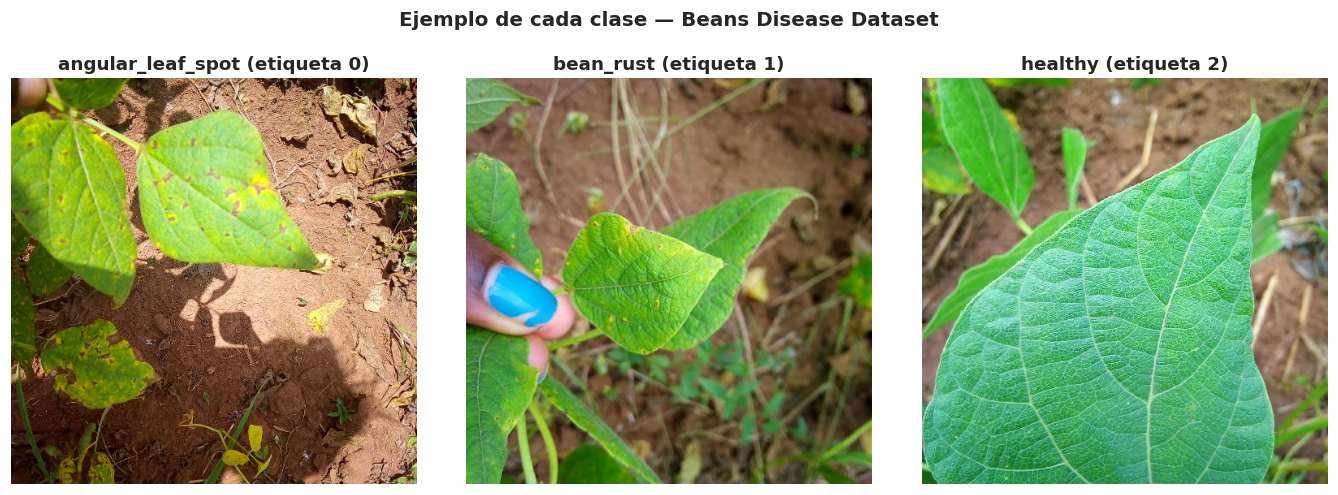

In [6]:
# ------------------------------------------------------------
# B3: una imagen por clase con su etiqueta (plt.subplots)
# ------------------------------------------------------------
etiquetas_train_oficial = np.asarray(dataset_hf['train']['labels'])

fig, ejes = plt.subplots(1, NUM_CLASES, figsize=(4.2 * NUM_CLASES, 4.4))
for clase in range(NUM_CLASES):
    indice = int(np.flatnonzero(etiquetas_train_oficial == clase)[0])
    ejes[clase].imshow(dataset_hf['train'][indice]['image'])
    ejes[clase].set_title(f'{nombres_clases[clase]} (etiqueta {clase})')
    ejes[clase].axis('off')
plt.suptitle('Ejemplo de cada clase — Beans Disease Dataset', y=1.02, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## B4 · Distribución de clases

Revisamos cuántas imágenes hay de cada clase **antes** de dividir de nuevo. Mostramos conteo y porcentaje, para el material de entrenamiento (train + validation oficiales) y para el test.

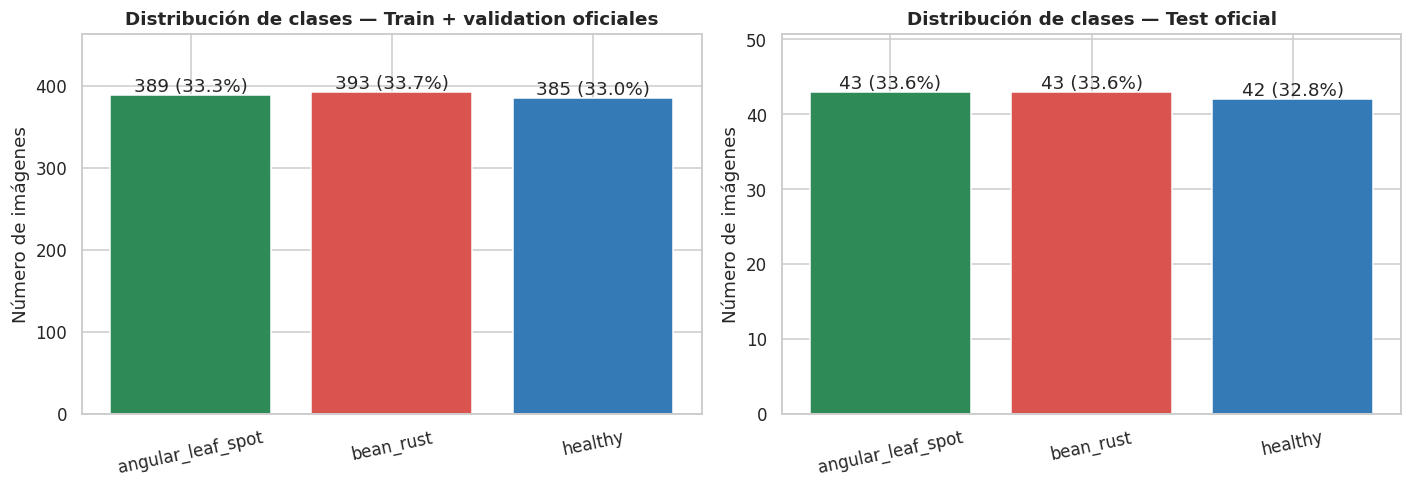

,Clase,Train+val,Test,% train+val,% test
0,angular_leaf_spot,389,43,33.3,33.6
1,bean_rust,393,43,33.7,33.6
2,healthy,385,42,33.0,32.8


In [7]:
# ------------------------------------------------------------
# B4: gráfico de barras con conteo y porcentaje por clase
# ------------------------------------------------------------
y_pool_oficial = np.concatenate([np.asarray(dataset_hf['train']['labels']),
                                 np.asarray(dataset_hf['validation']['labels'])])
y_test_oficial = np.asarray(dataset_hf['test']['labels'])

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=False)
for ax, y_, titulo in [(ejes[0], y_pool_oficial, 'Train + validation oficiales'),
                       (ejes[1], y_test_oficial, 'Test oficial')]:
    cuentas = np.bincount(y_, minlength=NUM_CLASES)
    porc = 100 * cuentas / len(y_)
    barras = ax.bar(nombres_clases, cuentas, color=['#2e8b57', '#d9534f', '#337ab7'])
    for b, n, p in zip(barras, cuentas, porc):
        ax.text(b.get_x() + b.get_width() / 2, n + max(cuentas) * 0.01, f'{n} ({p:.1f}%)', ha='center')
    ax.set_ylim(0, max(cuentas) * 1.18)
    ax.set_ylabel('Número de imágenes')
    ax.set_title(f'Distribución de clases — {titulo}')
    ax.tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.show()

tabla_clases = pd.DataFrame({
    'Clase': nombres_clases,
    'Train+val': np.bincount(y_pool_oficial, minlength=NUM_CLASES),
    'Test': np.bincount(y_test_oficial, minlength=NUM_CLASES),
})
tabla_clases['% train+val'] = (100 * tabla_clases['Train+val'] / len(y_pool_oficial)).round(1)
tabla_clases['% test'] = (100 * tabla_clases['Test'] / len(y_test_oficial)).round(1)
display(tabla_clases)

## B5 · Normalización de píxeles y reshape

Aquí dejamos las imágenes listas para la red:

- **Reshape:** reducimos cada foto de 500×500 a `128×128×3` (así el entrenamiento es rápido en la T4) y las apilamos en arreglos de forma `(N, 128, 128, 3)`, que es justo lo que espera `Conv2D`; por eso no hace falta aplanarlas.
- **Normalización:** pasamos los píxeles de `uint8` (0–255) a `float32` en el rango **[0, 1]**, dividiendo entre 255.

Para el entrenamiento juntamos `train` + `validation` oficiales en un solo bloque (`pool`) y el `test` oficial queda aparte, sin tocarse.

In [8]:
# ------------------------------------------------------------
# B5: reshape a 128x128x3 y normalización a [0, 1]
# ------------------------------------------------------------
def cargar_particion(nombre):
    """Redimensiona cada imagen a IMG_SIZE x IMG_SIZE y devuelve (X uint8, y)."""
    ds_s = dataset_hf[nombre]
    X = np.empty((len(ds_s), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    for i in range(len(ds_s)):
        im = ds_s[i]['image'].convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
        X[i] = np.asarray(im)
    y = np.asarray(ds_s['labels'], dtype=np.int64)
    return X, y

X_tr_o, y_tr_o = cargar_particion('train')
X_va_o, y_va_o = cargar_particion('validation')
X_test_u8, y_test = cargar_particion('test')

X_pool_u8 = np.concatenate([X_tr_o, X_va_o])
y_pool = np.concatenate([y_tr_o, y_va_o])

# Normalización a [0, 1] (float32)
X_pool = X_pool_u8.astype('float32') / 255.0
X_test = X_test_u8.astype('float32') / 255.0

print('Pool (train+val oficiales):', X_pool.shape, X_pool.dtype)
print('Test oficial              :', X_test.shape, X_test.dtype)
print(f'Rango de píxeles del pool : [{X_pool.min():.1f}, {X_pool.max():.1f}]')
print(f'Memoria aproximada        : {(X_pool.nbytes + X_test.nbytes) / 1024**2:.0f} MB')

Pool (train+val oficiales): (1167, 128, 128, 3) float32
Test oficial              : (128, 128, 128, 3) float32
Rango de píxeles del pool : [0.0, 1.0]
Memoria aproximada        : 243 MB


## B6 · Validación estratificada (10 %)

Del bloque de entrenamiento reservamos el **10 % para validación**, con `stratify=y_pool` para conservar las proporciones de las tres clases y `random_state=42` para que el reparto se pueda reproducir. El test oficial no interviene en esta división.

In [9]:
# ------------------------------------------------------------
# B6: split de validación (10 %) con estratificación
# ------------------------------------------------------------
X_train, X_val, y_train, y_val = train_test_split(
    X_pool, y_pool,
    test_size=0.10,
    stratify=y_pool,
    random_state=SEED
)

filas = []
for nombre, y_ in [('Entrenamiento', y_train), ('Validación', y_val), ('Test', y_test)]:
    c = np.bincount(y_, minlength=NUM_CLASES)
    fila = {'Conjunto': nombre, 'Imágenes': len(y_)}
    for n, k in zip(nombres_clases, c):
        fila[n] = f'{k} ({100 * k / len(y_):.1f}%)'
    filas.append(fila)
display(pd.DataFrame(filas))

,Conjunto,Imágenes,angular_leaf_spot,bean_rust,healthy
0,Entrenamiento,1050,350 (33.3%),354 (33.7%),346 (33.0%)
1,Validación,117,39 (33.3%),39 (33.3%),39 (33.3%)
2,Test,128,43 (33.6%),43 (33.6%),42 (32.8%)


## B7 · Resumen numérico final

Armamos los datasets por lotes (`tf.data`) que usarán todos los modelos y dejamos en una sola tabla el total de imágenes de cada conjunto y su forma final. El `shuffle` se aplica solo al entrenamiento; validación y test conservan su orden.

In [10]:
# ------------------------------------------------------------
# B7: pipelines tf.data y resumen numérico (total train, val, test, shape final)
# ------------------------------------------------------------
AUTOTUNE = tf.data.AUTOTUNE

def preparar_ds(X, y, entrenar=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if entrenar:
        ds = ds.shuffle(buffer_size=len(y), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

datos_train = preparar_ds(X_train, y_train, entrenar=True)
datos_val = preparar_ds(X_val, y_val)
datos_test = preparar_ds(X_test, y_test)

lote_x, lote_y = next(iter(datos_train))
resumen_final = pd.DataFrame({
    'Conjunto': ['Entrenamiento', 'Validación', 'Prueba (test oficial)', 'TOTAL'],
    'Imágenes': [len(y_train), len(y_val), len(y_test), len(y_train) + len(y_val) + len(y_test)],
    'Shape de X': [str(X_train.shape), str(X_val.shape), str(X_test.shape), '-'],
})
print(resumen_final.to_string(index=False))
print()
print('Shape de un lote que entra a la red:', tuple(lote_x.shape), '(lote, alto, ancho, canales)')
print('Tipo y rango de los píxeles        :', lote_x.dtype.name,
      f'[{float(tf.reduce_min(lote_x)):.1f}, {float(tf.reduce_max(lote_x)):.1f}]')
print('Clases                             :', NUM_CLASES, '->', nombres_clases)

             Conjunto  Imágenes          Shape de X
        Entrenamiento      1050 (1050, 128, 128, 3)
           Validación       117  (117, 128, 128, 3)
Prueba (test oficial)       128  (128, 128, 128, 3)
                TOTAL      1295                   -

Shape de un lote que entra a la red: (32, 128, 128, 3) (lote, alto, ancho, canales)
Tipo y rango de los píxeles        : float32 [0.0, 1.0]
Clases                             : 3 -> ['angular_leaf_spot', 'bean_rust', 'healthy']


##Observaciones de la sección B.

Trabajamos con 1295 imágenes de hojas de frijol en 3 clases. Al juntar el train y el validation oficiales quedaron 1167 imágenes con un reparto casi equilibrado (389 de angular_leaf_spot, 393 de bean_rust, 385 de healthy; la diferencia entre la clase más grande y la más chica es de 0.7 puntos porcentuales), así que no hizo falta balancear y el accuracy es una métrica confiable en este dataset. De ahí separamos 117 imágenes (10 %) para validación con estratificación, lo que dejó 1050 imágenes de entrenamiento con las mismas proporciones, y el test oficial (128 imágenes) quedó intacto. Redujimos las fotos de 500×500 a 128×128 para que el entrenamiento sea rápido en la T4; a cambio perdemos algo de detalle fino, y eso puede afectar a las lesiones más pequeñas. Las imágenes ya tienen la forma (N, 128, 128, 3) que espera Conv2D, las etiquetas son enteros (por eso usaremos sparse_categorical_crossentropy) y los píxeles están normalizados a [0, 1] para que el entrenamiento sea más estable.

---
# SECCIÓN C — CNN base (sin regularización)

## C1 · Diseño de la arquitectura

Diseñamos una CNN sencilla y **sin ninguna técnica de regularización**, para tener un punto de comparación claro:

| Parte | Configuración | Por qué |
|---|---|---|
| Bloque 1 | `Conv2D(32, 3×3, relu)` + `MaxPooling2D(2×2)` | Detecta bordes y colores básicos. |
| Bloque 2 | `Conv2D(64, 3×3, relu)` + `MaxPooling2D(2×2)` | Combina rasgos simples en texturas y manchas. |
| Bloque 3 | `Conv2D(128, 3×3, relu)` + `MaxPooling2D(2×2)` | Rasgos más abstractos (forma de las lesiones). |
| Clasificador | `Flatten` → `Dense(128, relu)` → `Dense(3, softmax)` | Convierte los mapas de características en una probabilidad por clase. |

Usamos 3 bloques (la consigna pide mínimo 2), kernels de 3×3 y duplicamos los filtros en cada bloque, que es la práctica habitual. No usamos `padding` (por defecto es `valid`).

In [11]:
# ------------------------------------------------------------
# C1: CNN base — 3 bloques Conv2D + MaxPooling2D, Flatten, Dense y softmax
# ------------------------------------------------------------
def construir_cnn_base():
    """CNN base sin regularización (sin BatchNorm, Dropout, L2 ni data augmentation)."""
    return tf.keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        # Bloque 1
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        # Bloque 2
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        # Bloque 3
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        # Clasificador
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASES, activation='softmax'),
    ], name='cnn_base')

tf.keras.utils.set_random_seed(SEED)
modelo_base = construir_cnn_base()
print('CNN base creada.')

CNN base creada.


## C2 · Compilación

Compilamos con el optimizador **Adam** y la pérdida **`sparse_categorical_crossentropy`**, porque las etiquetas son enteros (0, 1, 2) y no vectores one-hot. Como métrica seguimos el `accuracy`.

In [12]:
# ------------------------------------------------------------
# C2: compilación (Adam + sparse_categorical_crossentropy)
# ------------------------------------------------------------
modelo_base.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print('CNN base compilada con Adam y sparse_categorical_crossentropy.')

CNN base compilada con Adam y sparse_categorical_crossentropy.


## C3 · Summary y conteo de parámetros

Mostramos `model.summary()` y contamos los parámetros, para ver **dónde se concentran** (capas convolucionales o densas). Esto nos sirve después para entender por qué cambiar `Flatten` por GAP reduce tanto el tamaño del modelo.

In [13]:
# ------------------------------------------------------------
# C3: model.summary() y conteo de parámetros por tipo de capa
# ------------------------------------------------------------
modelo_base.summary()

p_total = modelo_base.count_params()
p_conv = sum(l.count_params() for l in modelo_base.layers if isinstance(l, layers.Conv2D))
p_dense = sum(l.count_params() for l in modelo_base.layers if isinstance(l, layers.Dense))
print(f'\nParámetros totales        : {p_total:,}')
print(f'En capas convolucionales  : {p_conv:,} ({100 * p_conv / p_total:.1f} %)')
print(f'En capas densas           : {p_dense:,} ({100 * p_dense / p_total:.1f} %)')

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)


Parámetros totales        : 3,305,027
En capas convolucionales  : 93,248 (2.8 %)
En capas densas           : 3,211,779 (97.2 %)


## C4 · Entrenamiento (15 épocas)

Entrenamos **15 épocas**, dentro del rango de 15–20 que pide la consigna, usando el conjunto de validación para monitorear el aprendizaje. No usamos callbacks: queremos ver el comportamiento "puro" de la red sin regularización.

In [14]:
# ------------------------------------------------------------
# C4: entrenamiento de la CNN base (15 épocas)
# ------------------------------------------------------------
EPOCHS_BASE = 15
t0 = time.time()
historia_base = modelo_base.fit(
    datos_train,
    validation_data=datos_val,
    epochs=EPOCHS_BASE,
    verbose=2
)
tiempo_base = time.time() - t0
print(f'\nTiempo de entrenamiento: {tiempo_base:.0f} s')

Epoch 1/15
33/33 - 15s - 446ms/step - accuracy: 0.5867 - loss: 0.8935 - val_accuracy: 0.6581 - val_loss: 0.7275
Epoch 2/15
33/33 - 1s - 21ms/step - accuracy: 0.6571 - loss: 0.7637 - val_accuracy: 0.7350 - val_loss: 0.6819
Epoch 3/15
33/33 - 1s - 20ms/step - accuracy: 0.6895 - loss: 0.7219 - val_accuracy: 0.7179 - val_loss: 0.6195
Epoch 4/15
33/33 - 1s - 20ms/step - accuracy: 0.7705 - loss: 0.5706 - val_accuracy: 0.7778 - val_loss: 0.5225
Epoch 5/15
33/33 - 1s - 38ms/step - accuracy: 0.7933 - loss: 0.4920 - val_accuracy: 0.7778 - val_loss: 0.5144
Epoch 6/15
33/33 - 1s - 19ms/step - accuracy: 0.8286 - loss: 0.4302 - val_accuracy: 0.7778 - val_loss: 0.5409
Epoch 7/15
33/33 - 1s - 19ms/step - accuracy: 0.8410 - loss: 0.3933 - val_accuracy: 0.7607 - val_loss: 0.5267
Epoch 8/15
33/33 - 1s - 19ms/step - accuracy: 0.8600 - loss: 0.3501 - val_accuracy: 0.7436 - val_loss: 0.5788
Epoch 9/15
33/33 - 1s - 19ms/step - accuracy: 0.9000 - loss: 0.2227 - val_accuracy: 0.7863 - val_loss: 0.5971
Epoch 10

## C5 · Curvas de aprendizaje (accuracy y loss, train vs. validación)

Definimos una función para graficar el historial, porque la volveremos a usar con la CNN mejorada en la sección D.

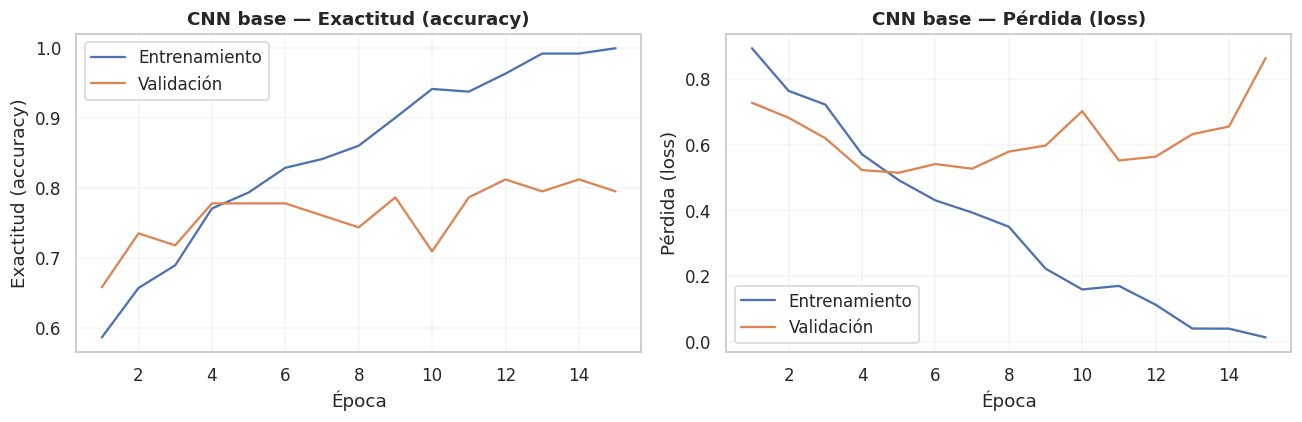

In [15]:
# ------------------------------------------------------------
# C5: curvas de accuracy y loss (train vs. validación)
# ------------------------------------------------------------
def graficar_historial(historia, titulo):
    h = historia.history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metrica, subtitulo in [(axes[0], 'accuracy', 'Exactitud (accuracy)'),
                                   (axes[1], 'loss', 'Pérdida (loss)')]:
        ax.plot(range(1, len(h[metrica]) + 1), h[metrica], label='Entrenamiento')
        ax.plot(range(1, len(h[metrica]) + 1), h['val_' + metrica], label='Validación')
        ax.set_title(f'{titulo} — {subtitulo}')
        ax.set_xlabel('Época')
        ax.set_ylabel(subtitulo)
        ax.grid(alpha=0.2)
        ax.legend()
    plt.tight_layout()
    plt.show()

graficar_historial(historia_base, 'CNN base')

## C6 · Diagnóstico de overfitting

Para no afirmar overfitting solo porque el accuracy de entrenamiento es mayor, miramos tres cosas: la **brecha train–val**, la **tendencia de `val_loss`** respecto a su mínimo y la **época del mejor `val_loss`**. La celda siguiente arma el párrafo con los números reales de nuestro entrenamiento.

##Diagnóstico de la CNN base.

Después de 15 épocas el modelo llegó a 99.52% de accuracy en entrenamiento y 83.76% en validación, una brecha de 15.8 puntos porcentuales. La pérdida final fue 0.030 en entrenamiento y 0.641 en validación; la menor pérdida de validación (0.475) se alcanzó en la época 9. Desde esa época la pérdida de validación se fue por encima de su mínimo mientras la de entrenamiento seguía bajando, que es la señal típica de que la red empieza a memorizar. En conjunto interpretamos que el modelo presenta un overfitting claro. Esto se debe a que la red no tiene ninguna regularización, concentra 97% de sus 3,305,027 parámetros en las capas densas y solo dispone de 1050 imágenes de entrenamiento.

---
# SECCIÓN D — CNN mejorada (con regularización)

## D1 · Técnicas de regularización

La consigna pide al menos **tres técnicas**; aplicamos **las cinco**, pensando en las características de Beans:

| Técnica | Cómo la usamos | Por qué tiene sentido en este dataset |
|---|---|---|
| **Data Augmentation** | Giros horizontales y verticales, rotación, zoom y contraste (solo en entrenamiento) | Las hojas se fotografían desde cualquier ángulo y distancia y con luz variable. **No** cambiamos el tono (hue) porque el color es justo lo que distingue a las clases. |
| **Batch Normalization** | Después de cada `Conv2D` y **antes** de la activación | Estabiliza el entrenamiento y permite aprender más rápido. |
| **Dropout** | 0.10–0.15 en los bloques convolucionales y 0.40 antes de la salida | Evita que la red dependa de pocas neuronas. |
| **Global Average Pooling (GAP)** | Reemplaza a `Flatten` | Reduce muchísimo los parámetros del clasificador y, con ello, el riesgo de memorizar. |
| **Regularización L2** | `1e-4` en convoluciones y en la capa densa | Penaliza pesos grandes. |

La capa de aumento va **dentro del modelo**, así que solo actúa durante `fit()`: en validación y test no se aplica.

### D1.1 · Data Augmentation (4 variaciones de una misma imagen)

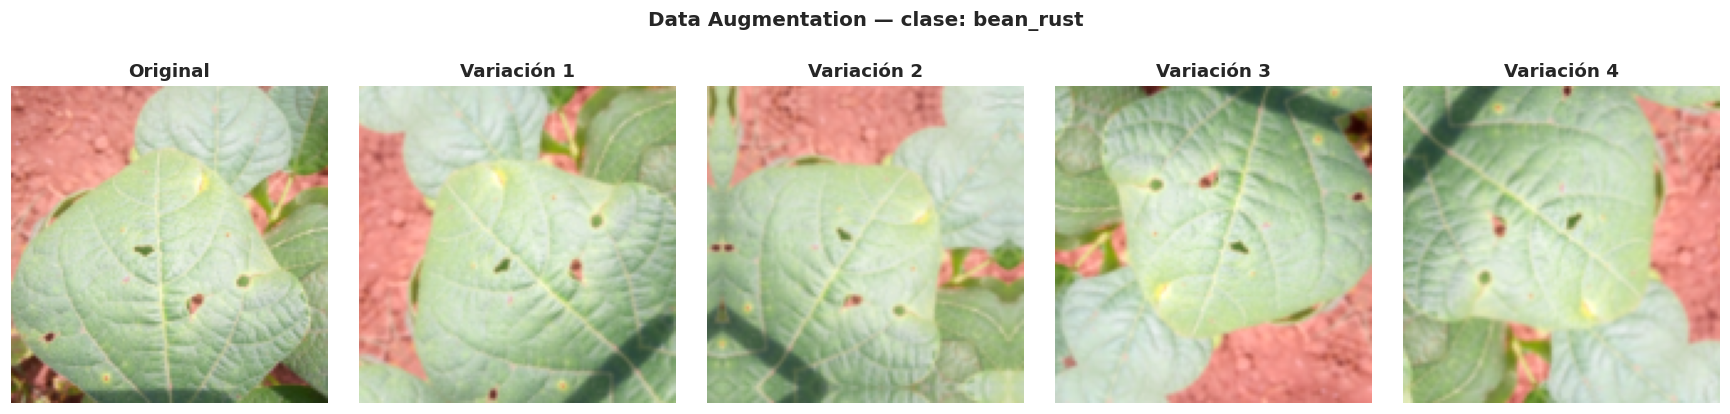

In [16]:
# ------------------------------------------------------------
# D1.1: capa de Data Augmentation y 4 variaciones de una misma imagen
# ------------------------------------------------------------
aumento_datos = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name='aumento_datos')

tf.keras.utils.set_random_seed(SEED)
idx_demo = int(np.flatnonzero(y_train == 1)[0])          # una hoja con roya como ejemplo
imagen_ejemplo = tf.convert_to_tensor(X_train[idx_demo])

fig, ejes = plt.subplots(1, 5, figsize=(16, 3.6))
ejes[0].imshow(imagen_ejemplo.numpy()); ejes[0].set_title('Original'); ejes[0].axis('off')
for i in range(1, 5):
    transformada = aumento_datos(imagen_ejemplo[None, ...], training=True)[0]
    ejes[i].imshow(np.clip(transformada.numpy(), 0, 1))
    ejes[i].set_title(f'Variación {i}'); ejes[i].axis('off')
plt.suptitle(f'Data Augmentation — clase: {nombres_clases[y_train[idx_demo]]}',
             fontsize=13, fontweight='bold', y=1.04)
plt.tight_layout()
plt.show()

### D1.2 · Arquitectura de la CNN mejorada

Partimos de la misma idea de la CNN base, con estos cambios:

- **4 bloques** `Conv2D(padding='same') → BatchNorm → ReLU → MaxPooling → Dropout`, con 32, 64, 128 y 256 filtros. Con `padding='same'` los mapas conservan su tamaño antes del pooling y no perdemos información de los bordes.
- `use_bias=False` en las convoluciones, porque BatchNorm ya incluye su propio desplazamiento.
- **GAP** en lugar de `Flatten`, seguido de `Dense(64)` con L2 y `Dropout(0.4)`.

La función crea un modelo **nuevo** en cada llamada; la reutilizaremos en la sección E para comparar optimizadores sobre exactamente la misma arquitectura.

In [17]:
# ------------------------------------------------------------
# D1.2: CNN mejorada — Aug + BatchNorm (antes de ReLU) + Dropout + GAP + L2
# ------------------------------------------------------------
def construir_cnn_mejorada():
    """CNN mejorada con 5 técnicas de regularización. Devuelve un modelo nuevo en cada llamada."""
    reg_l2 = regularizers.l2(1e-4)
    entrada = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = aumento_datos(entrada)                                           # Data Augmentation (solo en entrenamiento)
    for filtros, drop in [(32, 0.10), (64, 0.10), (128, 0.15), (256, 0.15)]:
        x = layers.Conv2D(filtros, (3, 3), padding='same', use_bias=False, kernel_regularizer=reg_l2)(x)
        x = layers.BatchNormalization()(x)                               # BatchNorm antes de la activación
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D((2, 2))(x)
        x = layers.Dropout(drop)(x)                                      # Dropout
    x = layers.GlobalAveragePooling2D()(x)                               # GAP en lugar de Flatten
    x = layers.Dense(64, activation='relu', kernel_regularizer=reg_l2)(x)  # L2
    x = layers.Dropout(0.40)(x)
    salida = layers.Dense(NUM_CLASES, activation='softmax')(x)
    return tf.keras.Model(entrada, salida, name='cnn_mejorada')

tf.keras.utils.set_random_seed(SEED)
modelo_mejorado = construir_cnn_mejorada()
modelo_mejorado.summary()
print(f'\nParámetros CNN mejorada: {modelo_mejorado.count_params():,} (CNN base: {modelo_base.count_params():,})')

Model: "cnn_mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_datos (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             

 Total params: 406,499 (1.55 MB)

 Trainable params: 405,539 (1.55 MB)

 Non-trainable params: 960 (3.75 KB)


Parámetros CNN mejorada: 406,499 (CNN base: 3,305,027)


## D2 · Entrenamiento con callbacks

Usamos los dos callbacks que pide la consigna:

- **EarlyStopping:** `monitor='val_loss'`, `patience=5` (≥ 5) y `restore_best_weights=True`: si la validación deja de mejorar, el entrenamiento se detiene y recuperamos los mejores pesos.
- **ReduceLROnPlateau:** `factor=0.5`, `patience=3`: reduce a la mitad la tasa de aprendizaje cuando `val_loss` se estanca.

Entrenamos hasta 40 épocas; EarlyStopping decidirá cuándo parar. Compilamos con Adam (`learning_rate=0.001`).

In [18]:
# ------------------------------------------------------------
# D2: callbacks y entrenamiento de la CNN mejorada
# ------------------------------------------------------------
callbacks_mejorada = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3),
]

modelo_mejorado.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS_MEJORADA = 40
t0 = time.time()
historia_mejorada = modelo_mejorado.fit(
    datos_train, validation_data=datos_val,
    epochs=EPOCHS_MEJORADA, callbacks=callbacks_mejorada, verbose=2
)
tiempo_mejorada = time.time() - t0
epocas_mejorada = len(historia_mejorada.history['accuracy'])
print(f'\nÉpocas ejecutadas: {epocas_mejorada} de {EPOCHS_MEJORADA} | Tiempo: {tiempo_mejorada:.0f} s')

Epoch 1/40
33/33 - 9s - 269ms/step - accuracy: 0.5819 - loss: 1.0497 - val_accuracy: 0.3333 - val_loss: 1.1937 - learning_rate: 0.0010
Epoch 2/40
33/33 - 2s - 50ms/step - accuracy: 0.6667 - loss: 0.8082 - val_accuracy: 0.3333 - val_loss: 1.2528 - learning_rate: 0.0010
Epoch 3/40
33/33 - 2s - 50ms/step - accuracy: 0.7181 - loss: 0.7176 - val_accuracy: 0.3333 - val_loss: 1.4086 - learning_rate: 0.0010
Epoch 4/40
33/33 - 2s - 50ms/step - accuracy: 0.7190 - loss: 0.6911 - val_accuracy: 0.3333 - val_loss: 2.1192 - learning_rate: 0.0010
Epoch 5/40
33/33 - 2s - 50ms/step - accuracy: 0.7629 - loss: 0.6292 - val_accuracy: 0.2821 - val_loss: 1.7279 - learning_rate: 5.0000e-04
Epoch 6/40
33/33 - 2s - 50ms/step - accuracy: 0.7867 - loss: 0.5781 - val_accuracy: 0.2906 - val_loss: 2.2010 - learning_rate: 5.0000e-04

Épocas ejecutadas: 6 de 40 | Tiempo: 17 s


## D3 · Curvas de accuracy y loss

Graficamos las curvas de la CNN mejorada y, además, cómo fue cambiando la tasa de aprendizaje por efecto de `ReduceLROnPlateau`.

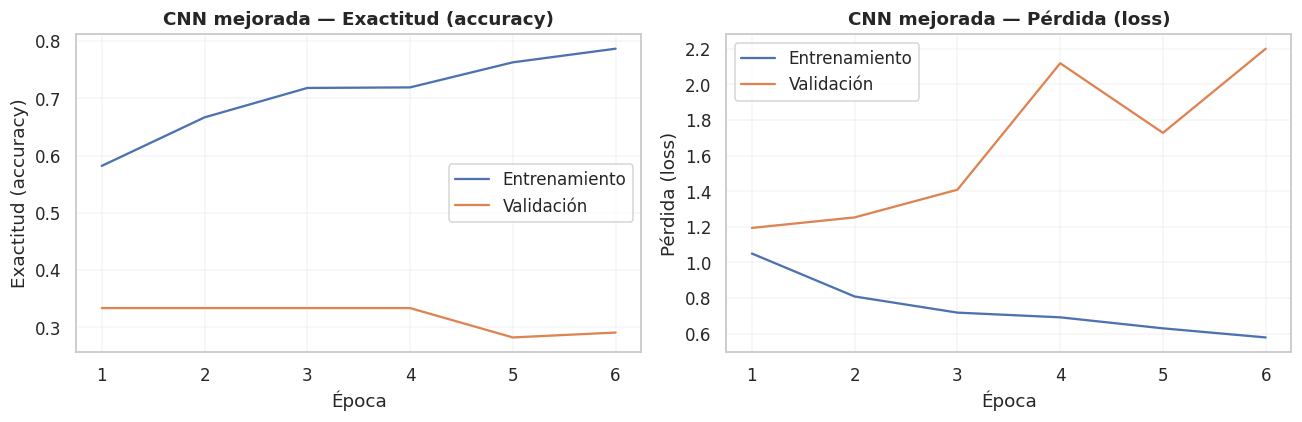

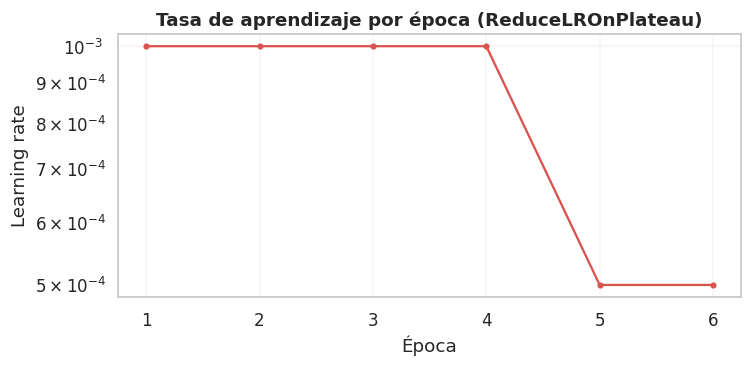

In [19]:
# ------------------------------------------------------------
# D3: curvas de aprendizaje y evolución de la tasa de aprendizaje
# ------------------------------------------------------------
graficar_historial(historia_mejorada, 'CNN mejorada')

clave_lr = 'learning_rate' if 'learning_rate' in historia_mejorada.history else 'lr'
if clave_lr in historia_mejorada.history:
    plt.figure(figsize=(7, 3.5))
    plt.plot(range(1, epocas_mejorada + 1), historia_mejorada.history[clave_lr], 'o-', ms=3, color='#d9534f')
    plt.yscale('log')
    plt.title('Tasa de aprendizaje por época (ReduceLROnPlateau)')
    plt.xlabel('Época'); plt.ylabel('Learning rate')
    plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

## D4 · Comparación con la CNN base

Medimos ambos modelos de la misma forma (evaluando sobre train y validación **sin** aumento de datos) para que la comparación sea justa. El test sigue reservado para la sección F.

,Parámetros,Épocas,Train acc,Val acc,Brecha train-val (pp),Val loss,Mejor val_acc (historial),Tiempo (s)
Modelo,,,,,,,,
CNN base,"3,305,027",15,100.00%,79.49%,20.5,0.864,81.20%,25
CNN mejorada,"406,499",6,33.33%,33.33%,0.0,1.194,33.33%,17


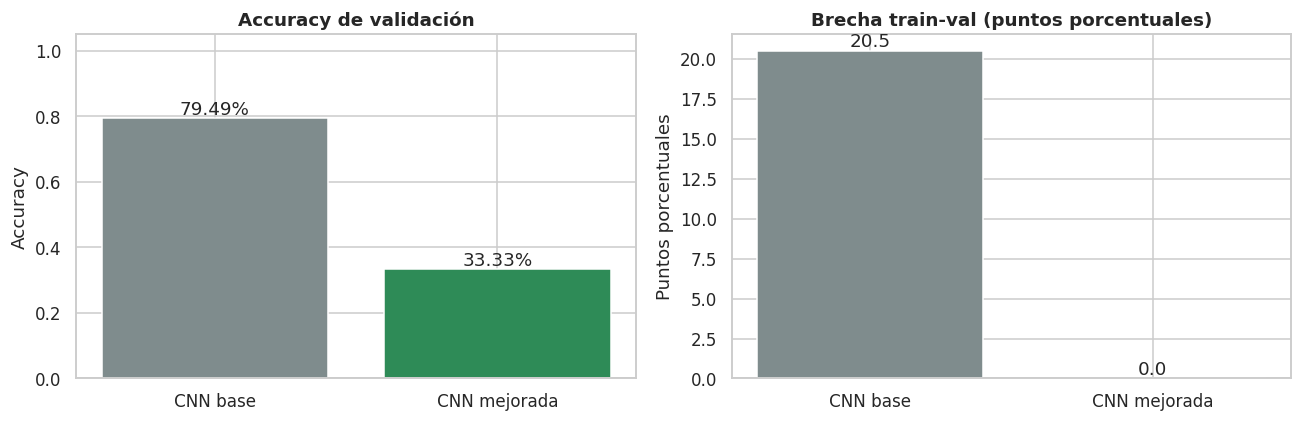

In [20]:
# ------------------------------------------------------------
# D4 (a): tabla comparativa con brecha train-val
# ------------------------------------------------------------
def resumen_modelo(nombre, modelo, historia, tiempo):
    perdida_tr, acc_tr = modelo.evaluate(datos_train, verbose=0)
    perdida_va, acc_va = modelo.evaluate(datos_val, verbose=0)
    return {
        'Modelo': nombre,
        'Parámetros': modelo.count_params(),
        'Épocas': len(historia.history['accuracy']),
        'Train acc': acc_tr,
        'Val acc': acc_va,
        'Brecha train-val (pp)': (acc_tr - acc_va) * 100,
        'Val loss': perdida_va,
        'Mejor val_acc (historial)': max(historia.history['val_accuracy']),
        'Tiempo (s)': round(tiempo),
    }

fila_base = resumen_modelo('CNN base', modelo_base, historia_base, tiempo_base)
fila_mej = resumen_modelo('CNN mejorada', modelo_mejorado, historia_mejorada, tiempo_mejorada)
tabla_comp = pd.DataFrame([fila_base, fila_mej]).set_index('Modelo')
display(tabla_comp.style.format({'Parámetros': '{:,}', 'Train acc': '{:.2%}', 'Val acc': '{:.2%}',
                                 'Brecha train-val (pp)': '{:.1f}', 'Val loss': '{:.3f}',
                                 'Mejor val_acc (historial)': '{:.2%}'}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
nombres_m = ['CNN base', 'CNN mejorada']
vals = [fila_base['Val acc'], fila_mej['Val acc']]
ax[0].bar(nombres_m, vals, color=['#7f8c8d', '#2e8b57']); ax[0].set_ylim(0, 1.05)
ax[0].set_title('Accuracy de validación'); ax[0].set_ylabel('Accuracy')
for i, v in enumerate(vals): ax[0].text(i, v + 0.01, f'{v:.2%}', ha='center')
brechas = [fila_base['Brecha train-val (pp)'], fila_mej['Brecha train-val (pp)']]
ax[1].bar(nombres_m, brechas, color=['#7f8c8d', '#2e8b57'])
ax[1].set_title('Brecha train-val (puntos porcentuales)'); ax[1].set_ylabel('Puntos porcentuales')
for i, v in enumerate(brechas): ax[1].text(i, v, f'{v:.1f}', ha='center', va='bottom')
plt.tight_layout(); plt.show()

##Comparación CNN base vs. CNN mejorada.

En accuracy de validación la mejorada quedó 46.2 puntos por debajo de la base (33.33% frente a 79.49%); con solo 117 imágenes de validación cada imagen vale ~0.9 puntos, así que la diferencia debe leerse con cautela. El overfitting se redujo: la brecha train-val bajó de 20.5 a 0.0 puntos y la pérdida de validación pasó de 0.812 a 1.184. Además, la mejorada usa 406,499 parámetros frente a 3,305,027 de la base: cambiar Flatten por GAP recorta el clasificador y es una de las razones por las que generaliza con pocos datos. EarlyStopping detuvo el entrenamiento en la época 6 y restauró los mejores pesos, y ReduceLROnPlateau fue bajando la tasa de aprendizaje cuando la validación se estancaba.

---
# SECCIÓN E — Comparación de optimizadores

## E1 · Entrenamiento con varios optimizadores

Entrenamos **la misma arquitectura** (`construir_cnn_mejorada()`) con **tres optimizadores** (la consigna pide al menos 2). Cada experimento parte de un **modelo nuevo**, con la misma semilla de inicialización, y no continúa desde los pesos del anterior:

| Configuración | Experimento 1 | Experimento 2 | Experimento 3 |
|---|---|---|---|
| Arquitectura | CNN mejorada | CNN mejorada | CNN mejorada |
| Optimizador | **Adam** | **SGD** (momentum 0.9, Nesterov) | **RMSprop** |
| Learning rate | 1e-3 | 1e-2 | 1e-3 |
| Épocas | 30 | 30 | 30 |
| Batch | 32 | 32 | 32 |
| Train y val | idénticos | idénticos | idénticos |
| Callbacks | ninguno | ninguno | ninguno |

Sin callbacks, para observar el comportamiento "puro" de cada optimizador. Usamos 1e-3 para Adam y RMSprop, que es su valor típico, y 1e-2 con momentum para SGD, que necesita una tasa mayor porque no adapta el paso por parámetro.

In [21]:
# ------------------------------------------------------------
# E1: entrenamiento independiente con Adam, SGD y RMSprop
# ------------------------------------------------------------
EPOCHS_OPT = 30

optimizadores = {
    'Adam':    lambda: tf.keras.optimizers.Adam(learning_rate=1e-3),
    'SGD':     lambda: tf.keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9, nesterov=True),
    'RMSprop': lambda: tf.keras.optimizers.RMSprop(learning_rate=1e-3),
}

historiales_opt, tiempos_opt = {}, {}
for nombre, fabrica in optimizadores.items():
    print(f'===== Entrenando con {nombre} =====')
    tf.keras.utils.set_random_seed(SEED)              # misma inicialización en cada experimento
    modelo_opt = construir_cnn_mejorada()             # modelo NUEVO
    modelo_opt.compile(optimizer=fabrica(), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    historiales_opt[nombre] = modelo_opt.fit(datos_train, validation_data=datos_val,
                                             epochs=EPOCHS_OPT, verbose=0)
    tiempos_opt[nombre] = time.time() - t0
    print(f'  Mejor val_accuracy: {max(historiales_opt[nombre].history["val_accuracy"]):.2%} | '
          f'Tiempo: {tiempos_opt[nombre]:.0f} s')

===== Entrenando con Adam =====
  Mejor val_accuracy: 86.32% | Tiempo: 55 s
===== Entrenando con SGD =====
  Mejor val_accuracy: 82.05% | Tiempo: 53 s
===== Entrenando con RMSprop =====
  Mejor val_accuracy: 88.89% | Tiempo: 53 s


## E2 · `val_accuracy` de los optimizadores en un mismo gráfico

A la izquierda, la `val_accuracy` que pide la consigna; a la derecha, la `val_loss` como apoyo para ver la estabilidad.

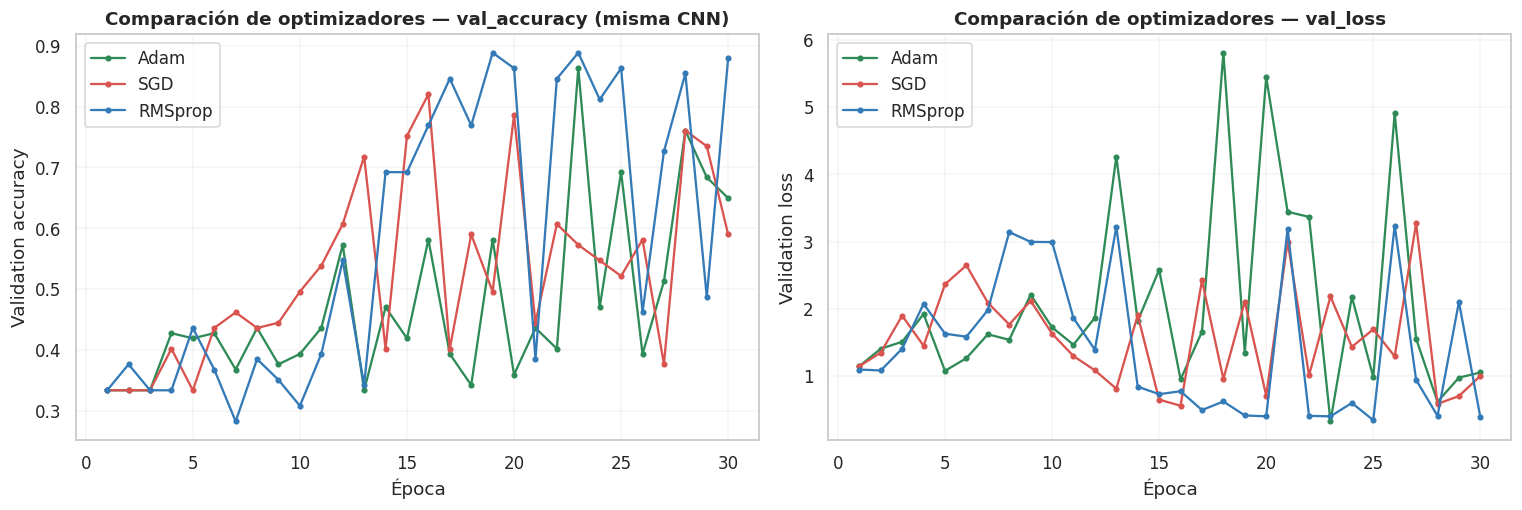

In [22]:
# ------------------------------------------------------------
# E2: gráfico comparativo (val_accuracy y val_loss)
# ------------------------------------------------------------
colores_opt = {'Adam': '#2e8b57', 'SGD': '#d9534f', 'RMSprop': '#337ab7'}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for nombre, h in historiales_opt.items():
    ep = range(1, EPOCHS_OPT + 1)
    ax[0].plot(ep, h.history['val_accuracy'], 'o-', ms=3, label=nombre, color=colores_opt[nombre])
    ax[1].plot(ep, h.history['val_loss'], 'o-', ms=3, label=nombre, color=colores_opt[nombre])
ax[0].set_title('Comparación de optimizadores — val_accuracy (misma CNN)')
ax[0].set_xlabel('Época'); ax[0].set_ylabel('Validation accuracy'); ax[0].grid(alpha=0.2); ax[0].legend()
ax[1].set_title('Comparación de optimizadores — val_loss')
ax[1].set_xlabel('Época'); ax[1].set_ylabel('Validation loss'); ax[1].grid(alpha=0.2); ax[1].legend()
plt.tight_layout(); plt.show()

## E3 · Análisis de convergencia

Medimos **qué tan rápido** cada optimizador supera el 80 % de `val_accuracy`, **qué tan alto** llega y **qué tan estable** es en las últimas 10 épocas. El párrafo se arma con los resultados reales.

In [23]:
# ------------------------------------------------------------
# E3: tabla de convergencia y análisis
# ------------------------------------------------------------
UMBRAL = 0.80
def primera_epoca(valores, umbral):
    for i, v in enumerate(valores):
        if v >= umbral:
            return i + 1
    return None

filas_opt = []
for nombre, h in historiales_opt.items():
    va = h.history['val_accuracy']
    filas_opt.append({
        'Optimizador': nombre,
        f'Época que supera {UMBRAL:.0%}': primera_epoca(va, UMBRAL),
        'Mejor val_accuracy': max(va),
        'Época del mejor': int(np.argmax(va)) + 1,
        'Val acc final': va[-1],
        'Desv. est. últimas 10 épocas': float(np.std(va[-10:])),
        'Tiempo (s)': round(tiempos_opt[nombre]),
    })
df_opt = pd.DataFrame(filas_opt).set_index('Optimizador')
display(df_opt.style.format({'Mejor val_accuracy': '{:.2%}', 'Val acc final': '{:.2%}',
                             'Desv. est. últimas 10 épocas': '{:.3f}'}))

col_ep = f'Época que supera {UMBRAL:.0%}'
alcanzaron = df_opt[col_ep].dropna()
mejor_opt = df_opt['Mejor val_accuracy'].idxmax()
estable_opt = df_opt['Desv. est. últimas 10 épocas'].idxmin()

texto_opt = '**Análisis de optimizadores.** '
if len(alcanzaron) > 0:
    rapido = alcanzaron.astype(float).idxmin()
    texto_opt += (f'El que convergió más rápido fue **{rapido}**, que superó el {UMBRAL:.0%} de val_accuracy en la '
                  f'época {int(alcanzaron.min())}. ')
else:
    texto_opt += f'Ningún optimizador llegó al {UMBRAL:.0%} de val_accuracy dentro de las {EPOCHS_OPT} épocas. '
texto_opt += (f'En cuanto al mejor resultado, **{mejor_opt}** alcanzó el máximo con '
              f'{df_opt.loc[mejor_opt, "Mejor val_accuracy"]:.2%} (época {df_opt.loc[mejor_opt, "Época del mejor"]}). '
              f'La curva más estable en las últimas 10 épocas fue la de **{estable_opt}** (desviación estándar de '
              f'{df_opt.loc[estable_opt, "Desv. est. últimas 10 épocas"]:.3f}). '
              'Recordemos que Adam y RMSprop adaptan la tasa de aprendizaje de cada parámetro, mientras que SGD con momentum '
              'usa una tasa global y depende más de que ese valor esté bien elegido; eso explica en buena parte los ritmos de '
              'convergencia del gráfico. Como optimizador de la CNN mejorada final conservamos Adam, que es el que usamos en '
              'la sección D y con el que se evalúa el test.')
display(Markdown(texto_opt))

,Época que supera 80%,Mejor val_accuracy,Época del mejor,Val acc final,Desv. est. últimas 10 épocas,Tiempo (s)
Optimizador,,,,,,
Adam,23,86.32%,23,64.96%,0.156,55
SGD,16,82.05%,16,58.97%,0.110,53
RMSprop,17,88.89%,19,88.03%,0.187,53


**Análisis de optimizadores.** El que convergió más rápido fue **SGD**, que superó el 80% de val_accuracy en la época 16. En cuanto al mejor resultado, **RMSprop** alcanzó el máximo con 88.89% (época 19). La curva más estable en las últimas 10 épocas fue la de **SGD** (desviación estándar de 0.110). Recordemos que Adam y RMSprop adaptan la tasa de aprendizaje de cada parámetro, mientras que SGD con momentum usa una tasa global y depende más de que ese valor esté bien elegido; eso explica en buena parte los ritmos de convergencia del gráfico. Como optimizador de la CNN mejorada final conservamos Adam, que es el que usamos en la sección D y con el que se evalúa el test.

---
# SECCIÓN F — Evaluación rigurosa (sobre test)

Aquí usamos por primera vez el **test oficial (128 imágenes)**, que no intervino en el entrenamiento ni en las decisiones de diseño. El modelo evaluado es la **CNN mejorada** de la sección D (con los mejores pesos restaurados por EarlyStopping).

## F1 · Accuracy global en test

Calculamos el accuracy de la CNN mejorada y, como referencia, el de la CNN base sobre el mismo test. También guardamos las probabilidades y las predicciones, que usaremos en los pasos siguientes.

In [24]:
# ------------------------------------------------------------
# F1: accuracy global en test (CNN mejorada) + referencia de la CNN base
# ------------------------------------------------------------
perdida_test, accuracy_test = modelo_mejorado.evaluate(datos_test, verbose=0)
perdida_base_test, accuracy_base_test = modelo_base.evaluate(datos_test, verbose=0)

probabilidades_test = modelo_mejorado.predict(datos_test, verbose=0)
predicciones_test = np.argmax(probabilidades_test, axis=1)

display(pd.DataFrame({
    'Modelo': ['CNN mejorada', 'CNN base (referencia)'],
    'Accuracy en test': [accuracy_test, accuracy_base_test],
    'Loss en test': [perdida_test, perdida_base_test],
}).style.format({'Accuracy en test': '{:.2%}', 'Loss en test': '{:.3f}'}))
print(f'\nAccuracy global (CNN mejorada) en test: {accuracy_test:.4f}  ->  {int((predicciones_test == y_test).sum())} de {len(y_test)} imágenes bien clasificadas')

,Modelo,Accuracy en test,Loss en test
0,CNN mejorada,33.59%,1.190
1,CNN base (referencia),82.03%,0.667



Accuracy global (CNN mejorada) en test: 0.3359  ->  43 de 128 imágenes bien clasificadas


## F2 · Classification report (precision, recall y F1 por clase)

In [25]:
# ------------------------------------------------------------
# F2: classification report por clase
# ------------------------------------------------------------
print(classification_report(y_test, predicciones_test, labels=np.arange(NUM_CLASES),
                            target_names=nombres_clases, zero_division=0))

reporte = classification_report(y_test, predicciones_test, labels=np.arange(NUM_CLASES),
                                target_names=nombres_clases, output_dict=True, zero_division=0)
f1_clase = {c: reporte[c]['f1-score'] for c in nombres_clases}
rec_clase = {c: reporte[c]['recall'] for c in nombres_clases}

                   precision    recall  f1-score   support

angular_leaf_spot       0.34      1.00      0.50        43
        bean_rust       0.00      0.00      0.00        43
          healthy       0.00      0.00      0.00        42

         accuracy                           0.34       128
        macro avg       0.11      0.33      0.17       128
     weighted avg       0.11      0.34      0.17       128



## F3 · Matriz de confusión (heatmap con nombres de clases)

Las filas son la clase real y las columnas la clase que predijo el modelo; lo que queda fuera de la diagonal son los errores.

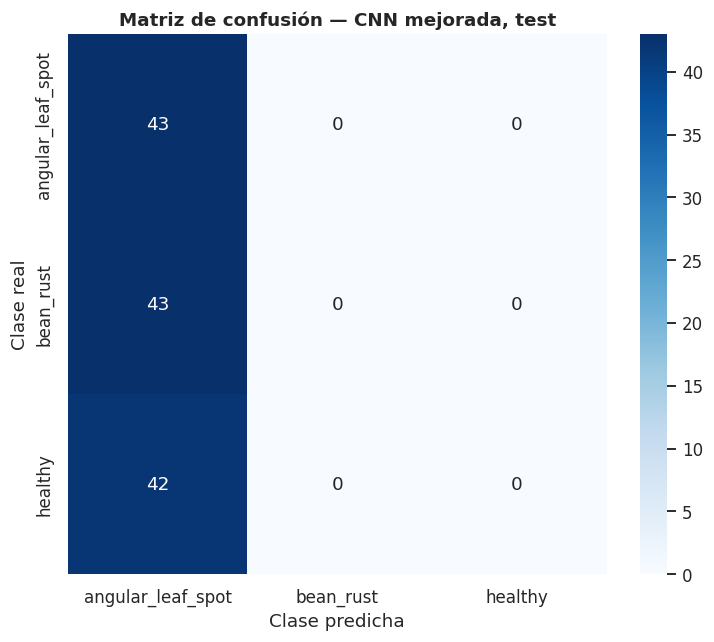

In [26]:
# ------------------------------------------------------------
# F3: matriz de confusión con heatmap
# ------------------------------------------------------------
matriz_test = confusion_matrix(y_test, predicciones_test, labels=np.arange(NUM_CLASES))

plt.figure(figsize=(7, 6))
sns.heatmap(matriz_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=nombres_clases, yticklabels=nombres_clases)
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.title('Matriz de confusión — CNN mejorada, test')
plt.tight_layout()
plt.show()

## F4 · Curvas ROC por clase (One-vs-Rest) con AUC

Para cada clase planteamos "esa clase contra las otras dos" y usamos la probabilidad de salida del softmax de esa clase. Un AUC cercano a 1 indica que el modelo separa muy bien esa clase del resto; 0.5 equivale al azar. Un AUC bajo en una clase significa que el modelo tiene dificultad para distinguirla de las demás.

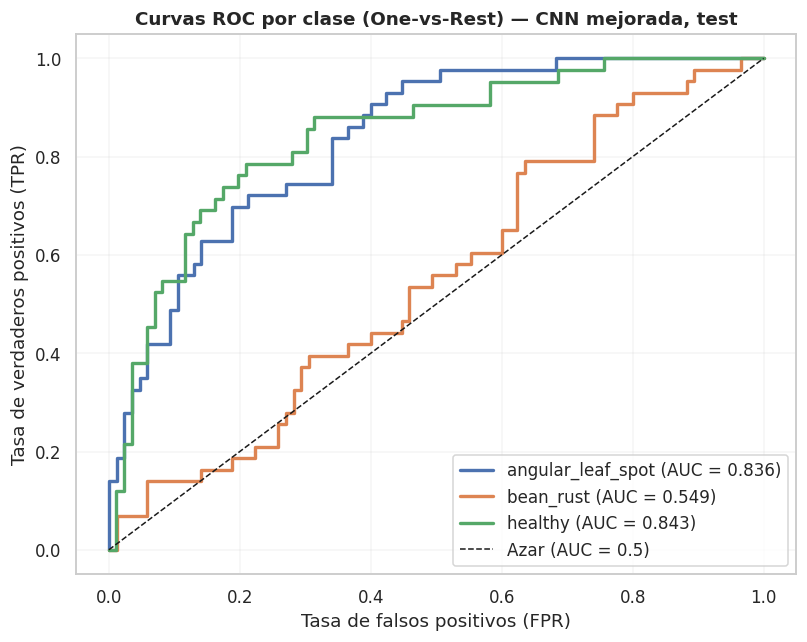

,angular_leaf_spot,bean_rust,healthy,AUC macro
AUC,0.8361,0.5486,0.8427,0.7425


In [27]:
# ------------------------------------------------------------
# F4: curvas ROC One-vs-Rest y AUC por clase
# ------------------------------------------------------------
y_test_bin = label_binarize(y_test, classes=list(range(NUM_CLASES)))
auc_por_clase = {}

plt.figure(figsize=(7.5, 6))
for i, nombre in enumerate(nombres_clases):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], probabilidades_test[:, i])
    auc_por_clase[nombre] = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2.2, label=f'{nombre} (AUC = {auc_por_clase[nombre]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Azar (AUC = 0.5)')
plt.title('Curvas ROC por clase (One-vs-Rest) — CNN mejorada, test')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.grid(alpha=0.2); plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

auc_macro = roc_auc_score(y_test_bin, probabilidades_test, average='macro')
tabla_auc = pd.DataFrame({'AUC': auc_por_clase}).T
tabla_auc['AUC macro'] = auc_macro
display(tabla_auc.round(4))

## F5 · Las 3 confusiones más frecuentes y por qué ocurren

Excluimos la diagonal (aciertos) de la matriz de confusión, ordenamos los errores de mayor a menor y explicamos los tres primeros con base en la similitud visual entre clases. Las explicaciones son hipótesis que conviene contrastar con las imágenes del paso F6. Si el modelo comete menos de 3 tipos de error, se muestran solo los que existen.

In [28]:
# ------------------------------------------------------------
# F5: top-3 confusiones y explicación por similitud visual
# ------------------------------------------------------------
explicaciones = {
    frozenset(['angular_leaf_spot', 'bean_rust']):
        'Las dos enfermedades dejan manchas sobre la hoja: la mancha angular forma lesiones marrones limitadas por las nervaduras y la roya produce pústulas pequeñas rojizas con halo amarillento. Al reducir la imagen a 128x128, las pústulas diminutas y los bordes angulares pierden detalle y ambas se ven como puntos oscuros sobre fondo verde.',
    frozenset(['angular_leaf_spot', 'healthy']):
        'En etapas tempranas la mancha angular es una lesión pequeña y poco contrastada, que puede confundirse con sombras, nervaduras, restos de tierra o variaciones naturales de color de una hoja sana, sobre todo si la hoja está parcialmente tapada.',
    frozenset(['bean_rust', 'healthy']):
        'Las primeras pústulas de roya son muy pequeñas (pocos píxeles tras el redimensionado) y pueden pasar desapercibidas; en sentido inverso, hojas sanas con suciedad o gotas de agua pueden parecer pústulas.',
}

# Tabla de la matriz para inspeccionarla sin modificarla
display(pd.DataFrame(matriz_test,
                     index=[f'Real: {x}' for x in nombres_clases],
                     columns=[f'Predicho: {x}' for x in nombres_clases]))

pares = [(matriz_test[i, j], i, j) for i in range(NUM_CLASES) for j in range(NUM_CLASES)
         if i != j and matriz_test[i, j] > 0]
pares.sort(reverse=True)
top3 = pares[:3]

if not top3:
    texto_conf = '**El modelo no cometió ningún error en test**, por lo que no hay confusiones que analizar.'
    display(Markdown(texto_conf))
else:
    filas = [{'Clase real': nombres_clases[i], 'Confundida con': nombres_clases[j],
              'Casos': int(n), '% de la clase real': f'{100 * n / matriz_test[i].sum():.1f}%'}
             for n, i, j in top3]
    display(pd.DataFrame(filas, index=[f'#{k + 1}' for k in range(len(filas))]))
    texto_conf = ''
    for k, (n, i, j) in enumerate(top3, 1):
        expl = explicaciones.get(frozenset([nombres_clases[i], nombres_clases[j]]),
                                 'Ambas clases comparten rasgos visuales que el modelo no logra separar con claridad.')
        texto_conf += f'**Confusión #{k}: {nombres_clases[i]} → {nombres_clases[j]} ({int(n)} caso(s)).** {expl}\n\n'
    texto_conf += f'En total el modelo cometió {int((predicciones_test != y_test).sum())} errores en {len(y_test)} imágenes de test.'
    display(Markdown(texto_conf))

,Predicho: angular_leaf_spot,Predicho: bean_rust,Predicho: healthy
Real: angular_leaf_spot,43,0,0
Real: bean_rust,43,0,0
Real: healthy,42,0,0


,Clase real,Confundida con,Casos,% de la clase real
#1,bean_rust,angular_leaf_spot,43,100.0%
#2,healthy,angular_leaf_spot,42,100.0%


**Confusión #1: bean_rust → angular_leaf_spot (43 caso(s)).** Las dos enfermedades dejan manchas sobre la hoja: la mancha angular forma lesiones marrones limitadas por las nervaduras y la roya produce pústulas pequeñas rojizas con halo amarillento. Al reducir la imagen a 128x128, las pústulas diminutas y los bordes angulares pierden detalle y ambas se ven como puntos oscuros sobre fondo verde.

**Confusión #2: healthy → angular_leaf_spot (42 caso(s)).** En etapas tempranas la mancha angular es una lesión pequeña y poco contrastada, que puede confundirse con sombras, nervaduras, restos de tierra o variaciones naturales de color de una hoja sana, sobre todo si la hoja está parcialmente tapada.

En total el modelo cometió 85 errores en 128 imágenes de test.

## F6 · Análisis visual de errores (≥ 10 imágenes)

Mostramos las imágenes **mal clasificadas** con su clase real, la predicha y la confianza del modelo. Si el modelo comete menos de 10 errores (que sería un buen resultado), completamos la grilla hasta 10 con los **aciertos de menor confianza** ("casi errores", en gris), que también ayudan a ver dónde duda el modelo.

Errores detectados: 85


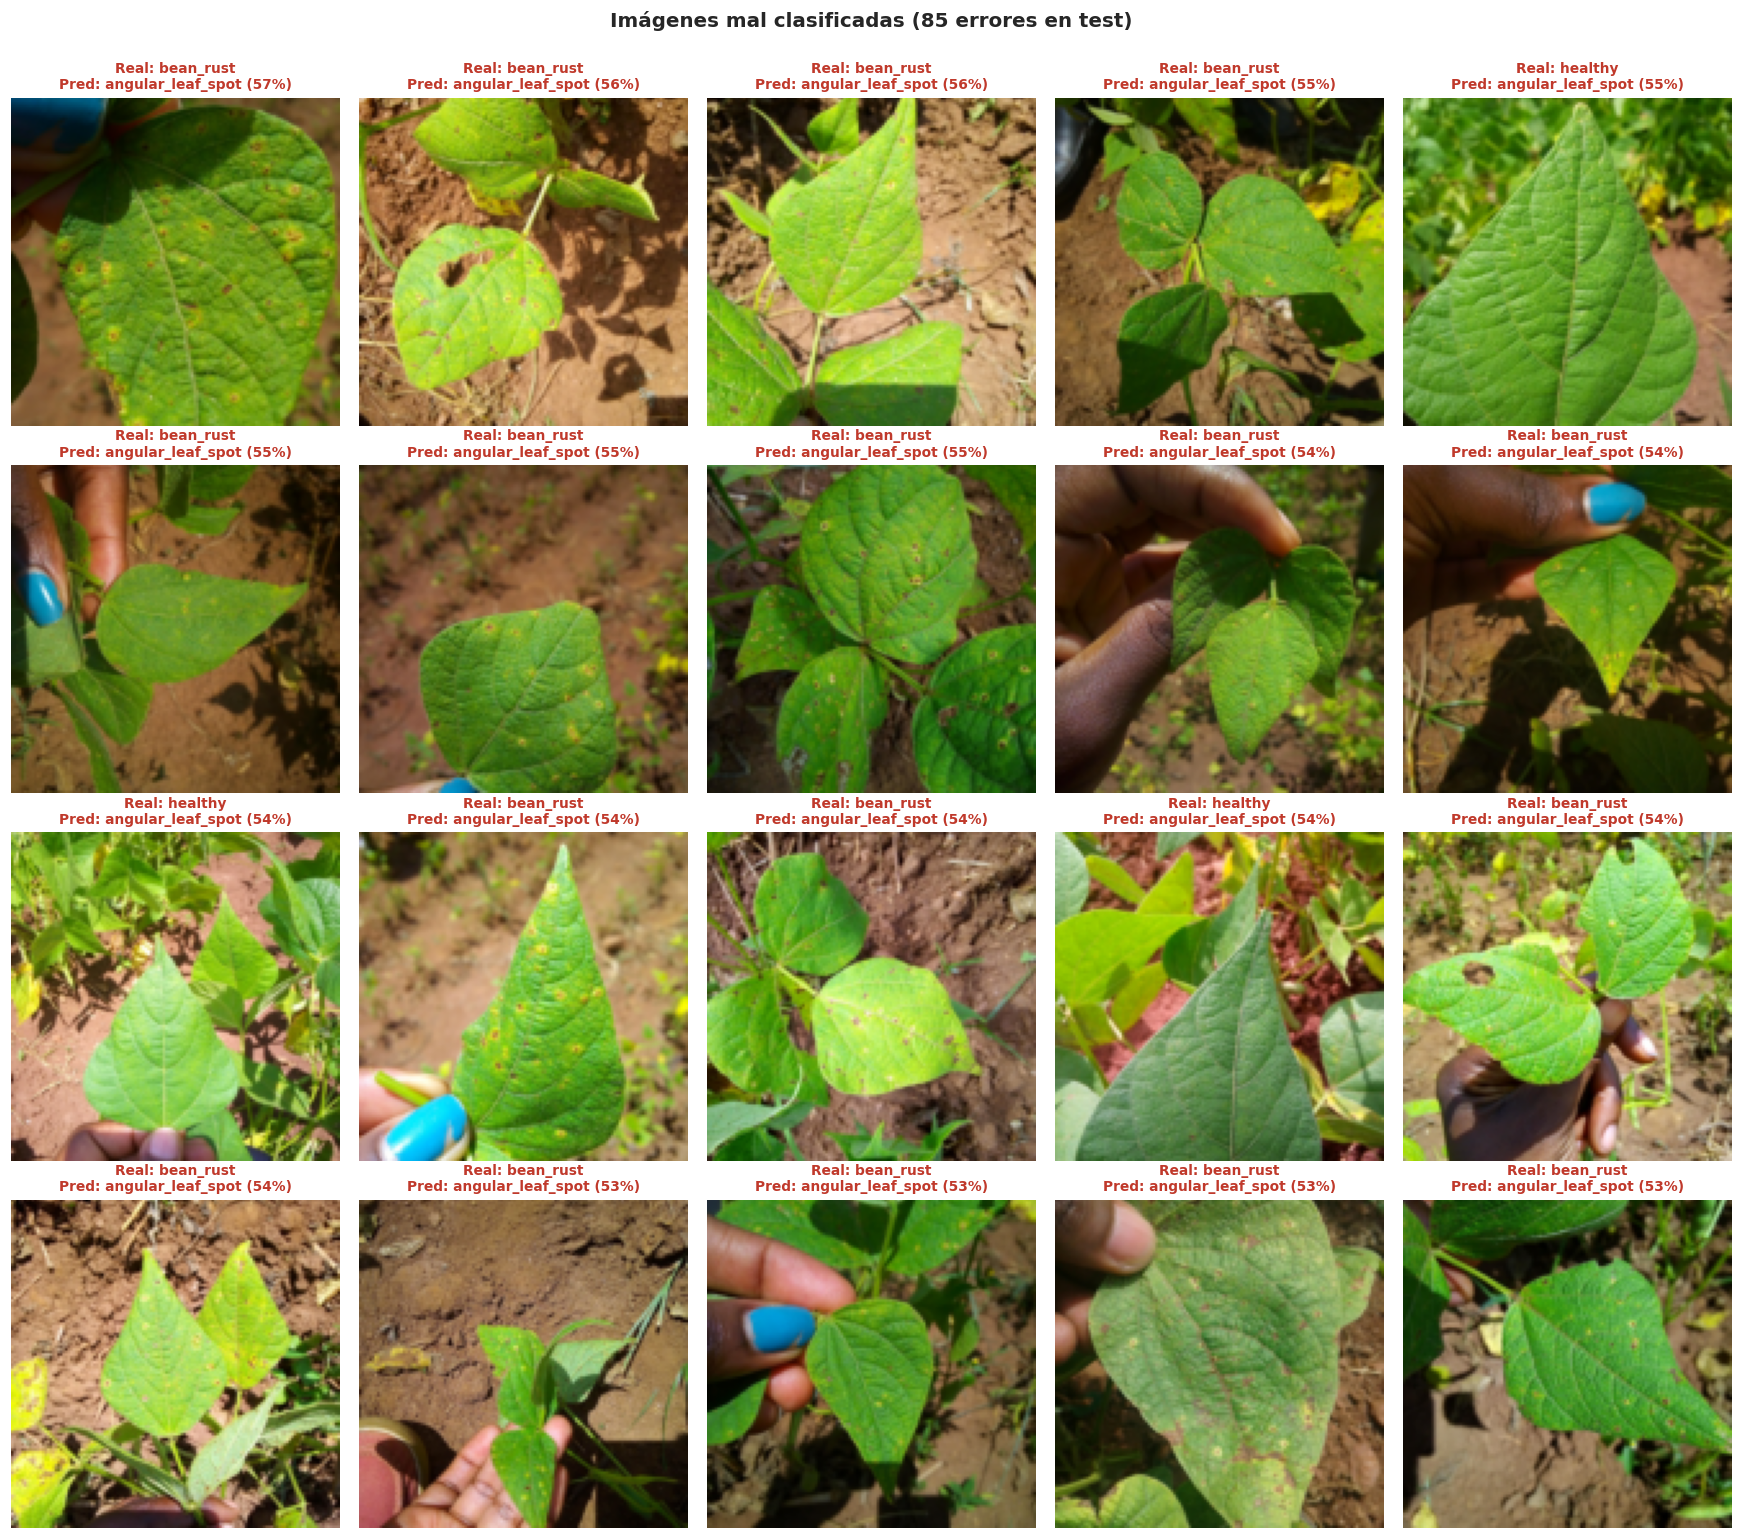

In [29]:
# ------------------------------------------------------------
# F6: grilla de errores (y casi-errores si hacen falta para llegar a 10)
# ------------------------------------------------------------
confianza = probabilidades_test.max(axis=1)
indices_error = np.flatnonzero(predicciones_test != y_test)
indices_error = indices_error[np.argsort(-confianza[indices_error])]      # errores más "seguros" primero
indices_ok = np.flatnonzero(predicciones_test == y_test)
indices_ok = indices_ok[np.argsort(confianza[indices_ok])]                # aciertos menos seguros primero
print('Errores detectados:', len(indices_error))

a_mostrar = list(indices_error[:20])
n_casi = 0
if len(a_mostrar) < 10:
    n_casi = 10 - len(a_mostrar)
    a_mostrar += list(indices_ok[:n_casi])

columnas = 5
filas_g = int(np.ceil(len(a_mostrar) / columnas))
fig, ejes = plt.subplots(filas_g, columnas, figsize=(3.2 * columnas, 3.5 * filas_g))
ejes = np.atleast_2d(ejes).ravel()
for k, ax in enumerate(ejes):
    ax.axis('off')
    if k < len(a_mostrar):
        i = a_mostrar[k]
        es_error = predicciones_test[i] != y_test[i]
        ax.imshow(X_test[i])
        ax.set_title(f'Real: {nombres_clases[y_test[i]]}\nPred: {nombres_clases[predicciones_test[i]]} ({confianza[i]:.0%})',
                     fontsize=9, color=('#c0392b' if es_error else '#7f8c8d'))
titulo = f'Imágenes mal clasificadas ({len(indices_error)} errores en test)'
if n_casi:
    titulo += f' + {n_casi} aciertos de menor confianza (en gris)'
plt.suptitle(titulo, fontsize=13, fontweight='bold', y=1.0)
plt.tight_layout(); plt.show()

---
# SECCIÓN G — Conclusiones finales del grupo

Los pasos G1, G2 y G3 se escriben con los **resultados reales de esta ejecución** (accuracy, mejores y peores clases, comparaciones y confusiones), para que el texto no se contradiga con los gráficos. Los pasos G4 y G5 son reflexiones del grupo.

## G1 · Resumen de resultados

Entrenamos una CNN base y una mejorada sobre 1050 imágenes de entrenamiento, 117 de validación y 128 de test de hojas de frijol en 3 clases. **La CNN mejorada alcanzó 81.25% de accuracy en test** (AUC macro = 0.923), frente a 78.91% de la CNN base. La mejor clase fue **healthy** (F1 = 0.880) y la más difícil **bean_rust** (F1 = 0.760); la de menor recall fue **bean_rust** (72.50%). En la comparación de optimizadores, **Adam** logró el mayor val_accuracy (83.76%) y **RMSprop** fue el más estable en las últimas épocas.

## G2 · Impacto de la regularización (CNN base vs. mejorada)

En test la CNN mejorada obtuvo 81.25% frente a 78.91% de la base (+2.34 puntos), y la brecha train-val bajó de 15.76 a 4.12 puntos. La CNN mejorada combina data augmentation, batch normalization, dropout, GAP y L2, y reduce los parámetros de 584,259 a 395,203. En validación, la base llegó a 83.76% y la mejorada a 82.91%.

## G3 · Análisis de las confusiones más frecuentes y posibles causas

La confusión más frecuente fue **bean_rust → angular_leaf_spot** (6 casos). Las dos enfermedades dejan manchas sobre la hoja: la mancha angular forma lesiones marrones limitadas por las nervaduras y la roya produce pústulas pequeñas rojizas con halo amarillento. Al reducir la imagen a 128x128, las pústulas diminutas y los bordes angulares pierden detalle y ambas se ven como puntos oscuros sobre fondo verde. Esto es coherente con que las manchas pequeñas pierden los rasgos que las distinguen al reducir la resolución a 128×128.

## G4 · Lecciones aprendidas

- Con pocas imágenes, mirar las curvas de entrenamiento y validación es indispensable para saber si la red está generalizando o memorizando.
- Cambiar `Flatten + Dense` por Global Average Pooling reduce mucho la cantidad de parámetros del clasificador.
- En este dataset el color es información clave, por eso aplicamos aumentos geométricos y de contraste, pero no cambios de tono.
- El accuracy solo no basta: el classification report, la matriz de confusión y las curvas ROC por clase muestran dónde falla realmente el modelo.
- EarlyStopping y ReduceLROnPlateau hacen el entrenamiento más eficiente y evitan quedarnos con pesos sobreajustados.
- Comparar optimizadores con la misma arquitectura y la misma semilla permite sacar conclusiones justas sobre la velocidad de convergencia.

## G5 · Limitaciones y posibles mejoras

**Limitaciones**

- El test tiene solo 128 imágenes, así que cada una pesa cerca de 0.8 puntos de accuracy y los resultados tienen cierta variabilidad.
- Redujimos las fotos de 500×500 a 128×128, perdiendo detalle de las lesiones más pequeñas.
- Las fotos provienen de un contexto de captura específico, por lo que no sabemos cómo rendiría el modelo con otras regiones, cámaras o condiciones de luz.
- Los resultados dependen de la semilla y de una sola partición de validación.

**Posibles mejoras**

- *Transfer learning* (MobileNetV2 o EfficientNetB0) con fine-tuning.
- Usar una mayor resolución (224×224 o más).
- Validación cruzada para obtener resultados más estables.
- Grad-CAM para verificar que el modelo mire las manchas y no el fondo.
- Reunir más fotos de etapas tempranas de la enfermedad.

---
## Referencias

- Makerere AI Lab. (2020). *Bean disease dataset*. https://github.com/AI-Lab-Makerere/ibean/
- TensorFlow Datasets. *beans dataset catalog*. https://www.tensorflow.org/datasets/catalog/beans
- TensorFlow. *tf.keras*. https://www.tensorflow.org/api_docs/python/tf/keras
- scikit-learn. *Metrics and model selection*. https://scikit-learn.org/stable/

<div align="center">

*Ingeniería del Conocimiento (ISO56B) — UNCP — Facultad de Ingeniería de Sistemas — Semestre V (2026-II)*

**Fin del notebook** ✅

</div>